In [ ]:
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from europa_eutectic.gaia_sim import GaiaSim
from europa_eutectic.util import colors


AUX_BASE = Path("../../data")
shell_visc_sims = [json_path for json_path in Path(AUX_BASE / "shell_visc").glob("*.json")]
shell_complex_rheo_sims = [json_path for json_path in Path(AUX_BASE / "shell_complex_rheo").glob("*.json")]
constK_varA_sims = [json_path for json_path in Path(AUX_BASE / "shell_thermal_cond_expan" / "constK_varA").glob("*.json")]
varK_constA_sims= [json_path for json_path in Path(AUX_BASE  / "shell_thermal_cond_expan" / "varK_constA").glob("*.json")]
varK_varA_sims= [json_path for json_path in Path(AUX_BASE    / "shell_thermal_cond_expan" / "varK_varA").glob("*.json")]
shell_tidal_sims = [json_path for json_path in Path(AUX_BASE / "shell_tidal").glob("*.json")]

base_cmap = sns.color_palette("icy_moon_2", as_cmap = True) # My custom colormap

# Attenuation fields for all 40 km eta 10^13 cases

In [2]:
################################################################
combo_list = shell_visc_sims + constK_varA_sims + varK_constA_sims + varK_varA_sims + shell_tidal_sims
D40_eta_13 = [simpath for simpath in combo_list if "D40km_eta1e+13" in simpath.name]
D40_eta_13 += [simpath for simpath in shell_complex_rheo_sims if "D40km" in simpath.name]

D40_eta_13_sims = [GaiaSim.load_from_json(simpath) for simpath in D40_eta_13]
D40_eta_13_sims

reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D40km_eta1e+13/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/constK_varA/Europa_D40km_eta1e+13/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D40km_eta1e+13/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/varA_varK/Europa_40km_eta1e+13/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/shell_tidal/Europa_D40km_eta1e+13_Tides/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D_1e13_thermal_comlex_rheo/Europa_D40km_eta2e-04/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic_2/Europa_D_1e13_thermal_comlex_rheo/Europa_D40km_eta2e-04/.


[GaiaSimcaseID='Europa_D40km_eta1e+13', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_visc', 
             "Shell thickness"=40000.00 (m),
             "log_10(eta_ref)"=13.00 log_10(Pa s),
             Ra=146181606.4293653, 
             final_time=15.9741 Myr),
 GaiaSimcaseID='Europa_D40km_eta1e+13', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/constK_varA', 
             "Shell thickness"=40000.00 (m),
             "log_10(eta_ref)"=13.00 log_10(Pa s),
             Ra=146181606.4293653, 
             final_time=21.3795 Myr),
 GaiaSimcaseID='Europa_D40km_eta1e+13', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/varK_constA', 
             "Shell thickness"=40000.00 (m),
             "log_10(eta_ref)"=13.00 log_10(Pa s),
             Ra=146181606.4293653, 
             final_time=35.9014 Myr),
 GaiaSimcaseID='Europa_D40km_eta1e+13', 
             parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/varK_varA', 
  

Europa_D40km_eta1e+13_shell_visc_atten.png


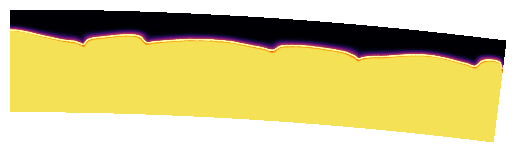

Europa_D40km_eta1e+13_constK_varA_atten.png


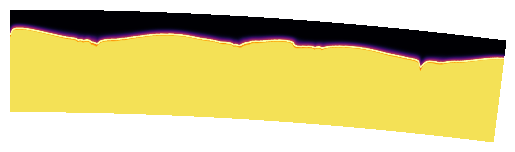

Europa_D40km_eta1e+13_varK_constA_atten.png


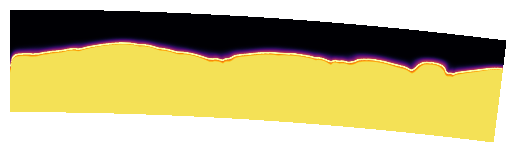

Europa_D40km_eta1e+13_varK_varA_atten.png


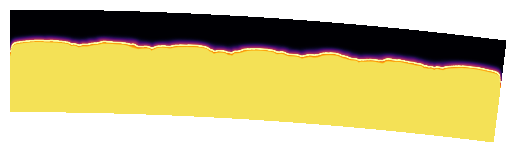

Europa_D40km_eta1e+13_Tides_shell_tidal_atten.png


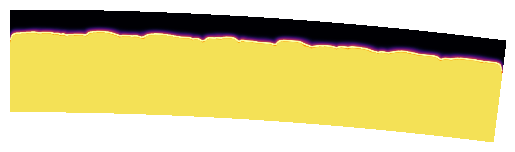

Europa_D40km_eta2e-04_shell_complex_rheo_atten.png


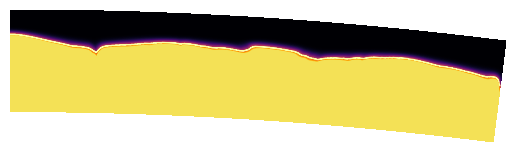

In [3]:
################################################################################################

sns.set_context("paper", font_scale=1.0) 
inferno_cmap_full = sns.color_palette("inferno", as_cmap=True)
inferno_cmap_partial = ListedColormap(inferno_cmap_full(np.linspace(0.0, 0.92, 256)))

for sim in D40_eta_13_sims: 
    field_data_low = sim.attenuation_interfaces[0].attenuation_2d.squeeze().copy() # Find a way to combine high 
    field_data_low[field_data_low > 100] = 100

    coords = np.array(sim.last_output.grid.shellCoords)
    y_coords = coords[:, :, 0] # Assuming Y is first dim based on previous code
    x_coords = coords[:, :, 1]
    levels = np.linspace(np.min(field_data_low), 100, 256)

    # Plot Contourf
    cont = plt.contourf(x_coords, y_coords, field_data_low,
                       levels=levels, cmap=inferno_cmap_partial,
                       extend="neither")

    high_loss_interface = sim.attenuation_interfaces[1]
    high_broadcast = np.broadcast_to(np.asarray(high_loss_interface.depth_to_attenuation_limit).reshape(1, -1), sim.depth_2d.shape)

    diff = np.abs(sim.depth_2d.squeeze() - high_broadcast)
    best_row_indices = np.argmin(diff, axis=0)

    clean_mask = np.zeros_like(sim.depth_2d.squeeze(), dtype=int)
    cols = np.arange(clean_mask.shape[1])
    clean_mask[best_row_indices, cols] = 1

    plt.contour(x_coords, y_coords, clean_mask, levels=[0.5], colors=inferno_cmap_full(1.0), linewidths=0.7)

    plt.gca().set_aspect('equal')
    plt.axis('off') # Hide axis numbers for cleaner look
    print(f"{sim.caseID}_{str(sim.parent_dir).split('/')[-1]}_atten.png")
    plt.savefig(f"{sim.caseID}_{str(sim.parent_dir).split('/')[-1]}_atten.png", transparent=True, dpi=300)
    plt.show()

